In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import zipfile

base = "/content/drive/MyDrive"
zip_path = "/content/Audio_Model_Results.zip"

output_files = [
    'audio_final_pretrained_ext.pt',
    'audio_fusion_final_pretrained_ext.npz',
    'manifest.csv',
    'audio_mel.npz',
    'audio_mel_norm.npz',
    'esc50_bg.npz',
    'audio_fusion_seed0.npz',
    'audio_fusion_ext_ensemble.npz',
    'audio_cv_models.pt',
    'audio_models_ext.pt'
]

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in output_files:
        path = os.path.join(base, f)

        if os.path.exists(path):
            z.write(path, arcname=f)
            print("Added:", f)
        else:
            print("Missing:", f)

print("\nZIP created:", os.path.exists(zip_path))
print("ZIP size:", round(os.path.getsize(zip_path)/1024**2, 2), "MB")

Added: audio_final_pretrained_ext.pt
Added: audio_fusion_final_pretrained_ext.npz
Added: manifest.csv
Added: audio_mel.npz
Added: audio_mel_norm.npz
Added: esc50_bg.npz
Added: audio_fusion_seed0.npz
Added: audio_fusion_ext_ensemble.npz
Added: audio_cv_models.pt
Added: audio_models_ext.pt

ZIP created: True
ZIP size: 547.73 MB


In [4]:
from google.colab import files

files.download("/content/Audio_Model_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
from collections import Counter

ROOT = '/content/drive/MyDrive/Audio'

ext_count = Counter()
ext_bytes = Counter()
sample_files = {}
total_files = 0

print("=== FOLDER STRUCTURE ===")
for dirpath, dirnames, filenames in os.walk(ROOT):
    depth = dirpath.replace(ROOT, '').count(os.sep)
    if depth <= 2:
        print('  ' * depth + os.path.basename(dirpath) + '/  (' + str(len(filenames)) + ' files)')
    for f in filenames:
        ext = os.path.splitext(f)[1].lower()
        ext_count[ext] += 1
        total_files += 1
        try:
            ext_bytes[ext] += os.path.getsize(os.path.join(dirpath, f))
        except Exception:
            pass
        if ext not in sample_files:
            sample_files[ext] = os.path.join(dirpath, f)

print("\n=== FILE TYPES ===")
for ext, n in ext_count.most_common():
    print(f"{ext or '(no ext)':12s}  {n:7d} files   {ext_bytes[ext]/1e9:8.3f} GB")

print(f"\nTOTAL: {total_files} files, {sum(ext_bytes.values())/1e9:.2f} GB")

print("\n=== ONE EXAMPLE OF EACH TYPE ===")
for ext, p in sample_files.items():
    print(f"{ext or '(no ext)':12s}  {p}")

=== FOLDER STRUCTURE ===

=== FILE TYPES ===

TOTAL: 0 files, 0.00 GB

=== ONE EXAMPLE OF EACH TYPE ===


In [ ]:
import os, random, soundfile as sf

ROOT = '/content/drive/MyDrive/Audio'

print("=== COUNTS PER SPLIT / CLASS ===")
for split in ['Train', 'Validation', 'Test']:
    for cls in ['Drone', 'Background']:
        p = os.path.join(ROOT, split, cls)
        if not os.path.isdir(p):
            print(f"{split}/{cls}: MISSING"); continue
        recs = sorted([d for d in os.listdir(p) if os.path.isdir(os.path.join(p,d))])
        n_files = sum(len(files) for _,_,files in os.walk(p))
        print(f"{split:11s} {cls:11s}  {len(recs):3d} subfolders, {n_files:4d} wav files")
        print(f"              examples: {recs[:6]}")

all_wavs = []
for dp,_,fs in os.walk(ROOT):
    for f in fs:
        if f.lower().endswith('.wav'):
            all_wavs.append(os.path.join(dp,f))

print("\n=== AUDIO PROPERTIES (10 random files) ===")
random.seed(0)
for p in random.sample(all_wavs, min(10, len(all_wavs))):
    i = sf.info(p)
    print(f"{i.samplerate} Hz | {i.channels} ch | {i.duration:6.2f} s | {i.subtype} | {p.replace(ROOT,'')}")

print("\n=== DURATION SUMMARY (all files) ===")
durs = [sf.info(p).duration for p in all_wavs]
print(f"count={len(durs)}  min={min(durs):.2f}s  max={max(durs):.2f}s  "
      f"mean={sum(durs)/len(durs):.2f}s  total={sum(durs)/60:.1f} min")

=== COUNTS PER SPLIT / CLASS ===
Train       Drone         16 subfolders,  118 wav files
              examples: ['Drone_1', 'Drone_10', 'Drone_11', 'Drone_12', 'Drone_13', 'Drone_14']
Train       Background    15 subfolders,   94 wav files
              examples: ['Background_1', 'Background_10', 'Background_11', 'Background_12', 'Background_13', 'Background_14']
Validation  Drone         13 subfolders,   20 wav files
              examples: ['Drone_1', 'Drone_10', 'Drone_11', 'Drone_12', 'Drone_13', 'Drone_2']
Validation  Background    12 subfolders,   12 wav files
              examples: ['Background_1', 'Background_10', 'Background_11', 'Background_12', 'Background_2', 'Background_3']
Test        Drone         14 subfolders,   21 wav files
              examples: ['Drone_1', 'Drone_10', 'Drone_11', 'Drone_12', 'Drone_13', 'Drone_14']
Test        Background    12 subfolders,   12 wav files
              examples: ['Background_1', 'Background_10', 'Background_11', 'Background_12', 'B

In [ ]:
import os, csv, re
from collections import defaultdict

ROOT = '/content/drive/MyDrive/Audio'
SPLITS = ['Train', 'Validation', 'Test']
CLASSES = ['Drone', 'Background']

rows = []
seg_by_rec = defaultdict(lambda: defaultdict(list))   # recording -> split -> [seg ids]

for split in SPLITS:
    for cls in CLASSES:
        base = os.path.join(ROOT, split, cls)
        if not os.path.isdir(base):
            continue
        for rec in sorted(os.listdir(base)):
            recdir = os.path.join(base, rec)
            if not os.path.isdir(recdir):
                continue
            for f in sorted(os.listdir(recdir)):
                if not f.lower().endswith('.wav'):
                    continue
                seg = os.path.splitext(f)[0]
                rows.append({
                    'path': os.path.join(recdir, f),
                    'split': split,
                    'label': cls,
                    'recording': rec,
                    'segment': seg,
                    'uid': f"{cls}|{rec}|{seg}",
                })
                seg_by_rec[f"{cls}/{rec}"][split].append(seg)

with open('/content/manifest.csv', 'w', newline='') as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0].keys()))
    w.writeheader(); w.writerows(rows)

print(f"manifest.csv written: {len(rows)} rows\n")

print("=== DOES A RECORDING APPEAR IN MORE THAN ONE SPLIT? ===")
shared = {r: d for r, d in seg_by_rec.items() if len(d) > 1}
print(f"{len(shared)} of {len(seg_by_rec)} recordings appear in multiple splits\n")

for rec in list(shared)[:6]:
    parts = " | ".join(
        f"{s}: n={len(seg_by_rec[rec][s])} segs={sorted(seg_by_rec[rec][s], key=lambda x: int(x) if x.isdigit() else 0)[:8]}"
        for s in SPLITS if s in seg_by_rec[rec]
    )
    print(f"{rec}\n   {parts}\n")

print("=== SEGMENT NUMBERS: overlapping or disjoint? ===")
for rec in list(shared)[:6]:
    sets = {s: set(seg_by_rec[rec][s]) for s in seg_by_rec[rec]}
    names = list(sets)
    overlaps = [f"{a}&{b}={len(sets[a] & sets[b])}"
                for i, a in enumerate(names) for b in names[i+1:]]
    print(f"{rec}: {', '.join(overlaps)}")

manifest.csv written: 277 rows

=== DOES A RECORDING APPEAR IN MORE THAN ONE SPLIT? ===
26 of 31 recordings appear in multiple splits

Drone/Drone_1
   Train: n=7 segs=['0', '1', '3', '4', '5', '8', '9'] | Validation: n=1 segs=['6'] | Test: n=2 segs=['2', '7']

Drone/Drone_10
   Train: n=4 segs=['0', '1', '2', '3'] | Validation: n=2 segs=['4', '9'] | Test: n=1 segs=['4']

Drone/Drone_11
   Train: n=1 segs=['0'] | Validation: n=2 segs=['5', '13'] | Test: n=2 segs=['0', '8']

Drone/Drone_12
   Train: n=7 segs=['0', '1', '2', '3', '6', '7', '8'] | Validation: n=1 segs=['3'] | Test: n=2 segs=['9', '19']

Drone/Drone_13
   Train: n=6 segs=['1', '2', '3', '5', '6', '7'] | Validation: n=3 segs=['12', '28', '35'] | Test: n=1 segs=['9']

Drone/Drone_14
   Train: n=16 segs=['0', '1', '2', '3', '4', '6', '7', '8'] | Test: n=3 segs=['9', '15', '34']

=== SEGMENT NUMBERS: overlapping or disjoint? ===
Drone/Drone_1: Train&Validation=0, Train&Test=0, Validation&Test=0
Drone/Drone_10: Train&Validation

In [ ]:
import os, csv, hashlib, random
from collections import defaultdict, Counter

ROOT = '/content/drive/MyDrive/Audio'
rows = list(csv.DictReader(open('/content/manifest.csv')))

# ---------- 4a. exact duplicate files ----------
by_hash = defaultdict(list)
for r in rows:
    h = hashlib.md5(open(r['path'],'rb').read()).hexdigest()
    r['md5'] = h
    by_hash[h].append(r)

dups = {h:v for h,v in by_hash.items() if len(v) > 1}
cross = {h:v for h,v in dups.items() if len({x['split'] for x in v}) > 1}
print(f"=== DUPLICATES ===")
print(f"{len(dups)} duplicated audio contents, {len(cross)} of them span >1 split")
for h,v in list(cross.items())[:5]:
    print("  " + " == ".join(f"{x['split']}/{x['label']}/{x['recording']}/{x['segment']}" for x in v))

# ---------- 4b. rebuild split by recording ----------
recs = defaultdict(list)
for r in rows:
    recs[(r['label'], r['recording'])].append(r)

TARGET = {'Train':0.70, 'Validation':0.15, 'Test':0.15}
new_split = {}
for label in ['Drone','Background']:
    items = sorted([(k,len(v)) for k,v in recs.items() if k[0]==label],
                   key=lambda x:-x[1])
    total = sum(n for _,n in items)
    quota = {s: TARGET[s]*total for s in TARGET}
    have  = {s: 0 for s in TARGET}
    random.seed(42)
    for k,n in items:
        s = max(TARGET, key=lambda s: quota[s]-have[s])
        new_split[k] = s
        have[s] += n
    print(f"\n{label}: {len(items)} recordings, {total} segments -> "
          + ", ".join(f"{s}={have[s]}" for s in TARGET))

for r in rows:
    r['grouped_split'] = new_split[(r['label'], r['recording'])]

print("\n=== NEW SPLIT: which recordings go where ===")
for s in ['Train','Validation','Test']:
    for label in ['Drone','Background']:
        rs = sorted({k[1] for k,v in new_split.items() if v==s and k[0]==label})
        print(f"{s:11s} {label:11s} {len(rs):2d} recs: {rs}")

# sanity: no recording in two splits
chk = defaultdict(set)
for r in rows: chk[(r['label'],r['recording'])].add(r['grouped_split'])
print("\nrecordings spanning >1 split:", sum(1 for v in chk.values() if len(v)>1))

with open('/content/manifest.csv','w',newline='') as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0].keys()))
    w.writeheader(); w.writerows(rows)
print("manifest.csv updated with md5 + grouped_split")

=== DUPLICATES ===
1 duplicated audio contents, 0 of them span >1 split

Drone: 16 recordings, 159 segments -> Train=113, Validation=23, Test=23

Background: 15 recordings, 118 segments -> Train=82, Validation=18, Test=18

=== NEW SPLIT: which recordings go where ===
Train       Drone       10 recs: ['Drone_1', 'Drone_11', 'Drone_12', 'Drone_13', 'Drone_14', 'Drone_15', 'Drone_16', 'Drone_2', 'Drone_4', 'Drone_6']
Train       Background   9 recs: ['Background_10', 'Background_11', 'Background_12', 'Background_2', 'Background_5', 'Background_6', 'Background_7', 'Background_8', 'Background_9']
Validation  Drone        3 recs: ['Drone_10', 'Drone_3', 'Drone_7']
Validation  Background   3 recs: ['Background_13', 'Background_15', 'Background_4']
Test        Drone        3 recs: ['Drone_5', 'Drone_8', 'Drone_9']
Test        Background   3 recs: ['Background_1', 'Background_14', 'Background_3']

recordings spanning >1 split: 0
manifest.csv updated with md5 + grouped_split


In [ ]:
!pip -q install librosa soundfile

import numpy as np, librosa, csv, os
from collections import Counter

SR, WIN, HOP = 16000, 1.0, 0.5      # sample rate, window sec, hop sec
N_MELS, N_FFT, HOP_LEN = 64, 400, 160

rows = list(csv.DictReader(open('/content/manifest.csv')))
X, y, meta = [], [], []

for i, r in enumerate(rows):
    wav, _ = librosa.load(r['path'], sr=SR, mono=True)
    w, h = int(WIN*SR), int(HOP*SR)
    for start in range(0, max(1, len(wav)-w+1), h):
        seg = wav[start:start+w]
        if len(seg) < w:
            seg = np.pad(seg, (0, w-len(seg)))
        m = librosa.feature.melspectrogram(y=seg, sr=SR, n_fft=N_FFT,
                                           hop_length=HOP_LEN, n_mels=N_MELS,
                                           fmin=20, fmax=SR//2)
        X.append(librosa.power_to_db(m, ref=np.max).astype(np.float32))
        y.append(1 if r['label']=='Drone' else 0)
        meta.append((r['grouped_split'], r['split'], r['recording'],
                     r['segment'], start/SR))
    if i % 50 == 0:
        print(f"{i}/{len(rows)} clips done")

X = np.stack(X); y = np.array(y, dtype=np.int64)
np.savez_compressed('/content/drive/MyDrive/audio_mel.npz',
                    X=X, y=y, meta=np.array(meta, dtype=object))

print(f"\nX shape: {X.shape}   y shape: {y.shape}")
print(f"dB range: {X.min():.1f} to {X.max():.1f}")
print("\nwindows per grouped split / class:")
print(Counter((m[0], 'Drone' if lbl else 'Background') for m, lbl in zip(meta, y)))
print("\nsaved to Drive: audio_mel.npz")

0/277 clips done
50/277 clips done
100/277 clips done
150/277 clips done
200/277 clips done
250/277 clips done

X shape: (5263, 64, 101)   y shape: (5263,)
dB range: -80.0 to 0.0

windows per grouped split / class:
Counter({('Train', 'Drone'): 2147, ('Train', 'Background'): 1558, ('Validation', 'Drone'): 437, ('Test', 'Drone'): 437, ('Test', 'Background'): 342, ('Validation', 'Background'): 342})

saved to Drive: audio_mel.npz


near-constant (silent/dead) windows: 0
per-window mean dB: min=-74.3  max=-18.8

mean dB  Drone=-44.2   Background=-58.0


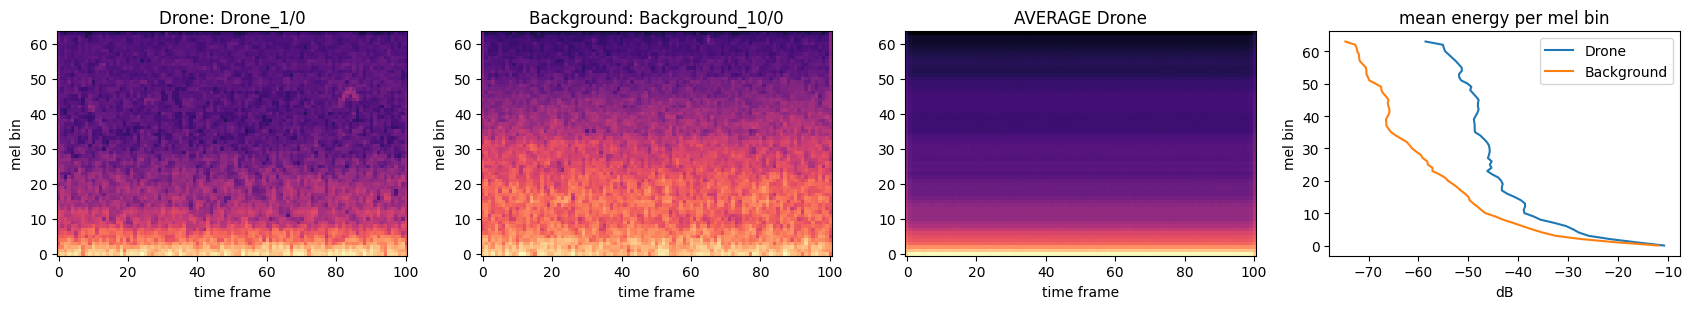


quick logistic-regression baseline on raw mel:
  train acc = 1.000
  TEST  acc = 0.906
  (majority-class baseline = 0.561)


In [ ]:
import numpy as np, matplotlib.pyplot as plt

d = np.load('/content/drive/MyDrive/audio_mel.npz', allow_pickle=True)
X, y, meta = d['X'], d['y'], d['meta']
split = np.array([m[0] for m in meta])

# --- 6a. any dead windows? ---
flat = X.reshape(len(X), -1)
dead = (flat.std(axis=1) < 1e-3).sum()
print(f"near-constant (silent/dead) windows: {dead}")
print(f"per-window mean dB: min={flat.mean(1).min():.1f}  max={flat.mean(1).max():.1f}")

# --- 6b. average spectrum per class ---
prof_d = X[y==1].mean(axis=(0,2))
prof_b = X[y==0].mean(axis=(0,2))
print(f"\nmean dB  Drone={X[y==1].mean():.1f}   Background={X[y==0].mean():.1f}")

fig, ax = plt.subplots(1, 4, figsize=(17,3.2))
for a, cls, name in [(ax[0],1,'Drone'), (ax[1],0,'Background')]:
    idx = np.where((y==cls) & (split=='Train'))[0][7]
    im = a.imshow(X[idx], origin='lower', aspect='auto', cmap='magma',
                  vmin=-80, vmax=0)
    a.set_title(f"{name}: {meta[idx][2]}/{meta[idx][3]}")
    a.set_xlabel('time frame'); a.set_ylabel('mel bin')

ax[2].imshow(X[y==1].mean(0), origin='lower', aspect='auto', cmap='magma')
ax[2].set_title('AVERAGE Drone'); ax[2].set_xlabel('time frame')

ax[3].plot(prof_d, range(len(prof_d)), label='Drone')
ax[3].plot(prof_b, range(len(prof_b)), label='Background')
ax[3].set_title('mean energy per mel bin'); ax[3].set_ylabel('mel bin')
ax[3].set_xlabel('dB'); ax[3].legend()
plt.tight_layout(); plt.show()

# --- 6c. how separable is this, crudely? ---
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
tr, te = split=='Train', split=='Test'
mu, sd = flat[tr].mean(0), flat[tr].std(0)+1e-6
clf = LogisticRegression(max_iter=2000).fit((flat[tr]-mu)/sd, y[tr])
print(f"\nquick logistic-regression baseline on raw mel:")
print(f"  train acc = {accuracy_score(y[tr], clf.predict((flat[tr]-mu)/sd)):.3f}")
print(f"  TEST  acc = {accuracy_score(y[te], clf.predict((flat[te]-mu)/sd)):.3f}")
print(f"  (majority-class baseline = {max(y[te].mean(), 1-y[te].mean()):.3f})")


In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

d = np.load('/content/drive/MyDrive/audio_mel.npz', allow_pickle=True)
X, y, meta = d['X'], d['y'], d['meta']
split = np.array([m[0] for m in meta])
tr, te = split=='Train', split=='Test'

def lr_acc(F, name):
    mu, sd = F[tr].mean(0), F[tr].std(0)+1e-6
    clf = LogisticRegression(max_iter=3000).fit((F[tr]-mu)/sd, y[tr])
    a = accuracy_score(y[te], clf.predict((F[te]-mu)/sd))
    print(f"{name:38s} TEST acc = {a:.3f}")
    return a

flat = X.reshape(len(X), -1)

# 7a. loudness ALONE (one single number per window)
lr_acc(flat.mean(1, keepdims=True), "loudness only (1 feature)")

# 7b. full spectrogram, as before
lr_acc(flat, "raw mel (baseline from step 6)")

# 7c. remove overall level: subtract each window's own mean
Xn = X - X.mean(axis=(1,2), keepdims=True)
lr_acc(Xn.reshape(len(X),-1), "level-removed (per-window mean sub)")

# 7d. remove level AND scale: full per-window standardisation
Xs = (X - X.mean(axis=(1,2), keepdims=True)) / (X.std(axis=(1,2), keepdims=True)+1e-6)
lr_acc(Xs.reshape(len(X),-1), "per-window standardised (shape only)")

# 7e. shape of the spectrum only, time averaged
prof = X.mean(axis=2)
prof = prof - prof.mean(1, keepdims=True)
lr_acc(prof, "spectral shape only (64 features)")

np.savez_compressed('/content/drive/MyDrive/audio_mel_norm.npz',
                    X=Xs.astype(np.float32), y=y, meta=meta)
print("\nsaved per-window standardised version: audio_mel_norm.npz")

loudness only (1 feature)              TEST acc = 0.770
raw mel (baseline from step 6)         TEST acc = 0.906
level-removed (per-window mean sub)    TEST acc = 0.893
per-window standardised (shape only)   TEST acc = 0.796
spectral shape only (64 features)      TEST acc = 0.932

saved per-window standardised version: audio_mel_norm.npz


In [ ]:
import numpy as np
d = np.load('/content/drive/MyDrive/audio_mel.npz', allow_pickle=True)
X, y, meta = d['X'], d['y'], d['meta']
Xn = (X - X.mean(axis=(1,2), keepdims=True)).astype(np.float32)
np.savez_compressed('/content/drive/MyDrive/audio_mel_norm.npz', X=Xn, y=y, meta=meta)
print("saved level-removed version:", Xn.shape, Xn.mean(), Xn.std())

saved level-removed version: (5263, 64, 101) 7.463433e-09 12.634915


In [ ]:
!cp /content/manifest.csv /content/drive/MyDrive/manifest.csv

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
for f in ['audio_mel.npz', 'audio_mel_norm.npz', 'manifest.csv']:
    p = '/content/drive/MyDrive/' + f
    print(f"{f:22s} {'OK' if os.path.exists(p) else 'MISSING':8s} "
          f"{os.path.getsize(p)/1e6:.1f} MB" if os.path.exists(p) else f"{f:22s} MISSING")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
audio_mel.npz          OK       97.0 MB
audio_mel_norm.npz     OK       113.9 MB
manifest.csv           OK       0.0 MB


In [ ]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

d = np.load('/content/drive/MyDrive/audio_mel_norm.npz', allow_pickle=True)
X, y, meta = d['X'], d['y'], d['meta']
split = np.array([m[0] for m in meta])
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print("device:", dev)

class DS(Dataset):
    def __init__(self, idx, train):
        self.X, self.y, self.train = X[idx], y[idx], train
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = self.X[i].copy()
        if self.train:
            x = x + np.random.uniform(-10, 10)                     # random gain
            x = np.roll(x, np.random.randint(-20, 20), axis=1)     # time shift
            for _ in range(2):                                     # SpecAugment
                f0 = np.random.randint(0, 56); x[f0:f0+np.random.randint(0,8)] = 0
                t0 = np.random.randint(0, 90); x[:, t0:t0+np.random.randint(0,12)] = 0
        return torch.from_numpy(x).unsqueeze(0), int(self.y[i])

class SmallCNN(nn.Module):
    def __init__(self, nf=32):
        super().__init__()
        def blk(i,o): return nn.Sequential(nn.Conv2d(i,o,3,padding=1),
                                           nn.BatchNorm2d(o), nn.ReLU(),
                                           nn.MaxPool2d(2))
        self.f = nn.Sequential(blk(1,nf), blk(nf,nf*2), blk(nf*2,nf*4),
                               nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.drop = nn.Dropout(0.5); self.fc = nn.Linear(nf*4, 2)
    def forward(self, x, emb=False):
        z = self.f(x)
        return z if emb else self.fc(self.drop(z))

def run(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    tr = DataLoader(DS(np.where(split=='Train')[0], True), 64, shuffle=True)
    va = DataLoader(DS(np.where(split=='Validation')[0], False), 256)
    te = DataLoader(DS(np.where(split=='Test')[0], False), 256)
    m = SmallCNN().to(dev)
    opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=1e-2)
    best_va, best_state = 0, None
    for ep in range(30):
        m.train()
        for xb, yb in tr:
            opt.zero_grad()
            F.cross_entropy(m(xb.to(dev)), yb.to(dev), label_smoothing=0.1).backward()
            opt.step()
        def acc(dl):
            m.eval(); c = n = 0
            with torch.no_grad():
                for xb, yb in dl:
                    c += (m(xb.to(dev)).argmax(1).cpu() == yb).sum().item(); n += len(yb)
            return c/n
        v = acc(va)
        if v > best_va: best_va, best_state = v, {k:t.clone() for k,t in m.state_dict().items()}
        if ep % 5 == 0: print(f"  ep{ep:2d} val={v:.3f}")
    m.load_state_dict(best_state)
    t = acc(te)
    print(f"seed {seed}: best val={best_va:.3f}  TEST={t:.3f}")
    return t, m

accs = []
for s in [0,1,2,3,4]:
    print(f"\n--- seed {s} ---")
    a, m = run(s); accs.append(a)
print(f"\nTEST over 5 seeds: {np.mean(accs):.3f} +/- {np.std(accs):.3f}   (floor to beat: 0.932)")

device: cuda

--- seed 0 ---
  ep 0 val=0.837
  ep 5 val=0.841
  ep10 val=0.834
  ep15 val=0.865
  ep20 val=0.661
  ep25 val=0.861
seed 0: best val=0.877  TEST=0.927

--- seed 1 ---
  ep 0 val=0.875
  ep 5 val=0.863
  ep10 val=0.841
  ep15 val=0.584
  ep20 val=0.805
  ep25 val=0.845
seed 1: best val=0.875  TEST=0.942

--- seed 2 ---
  ep 0 val=0.845
  ep 5 val=0.866
  ep10 val=0.841
  ep15 val=0.831
  ep20 val=0.610
  ep25 val=0.856
seed 2: best val=0.868  TEST=0.977

--- seed 3 ---
  ep 0 val=0.831
  ep 5 val=0.815
  ep10 val=0.860
  ep15 val=0.754
  ep20 val=0.825
  ep25 val=0.757
seed 3: best val=0.881  TEST=0.951

--- seed 4 ---
  ep 0 val=0.866
  ep 5 val=0.854
  ep10 val=0.845
  ep15 val=0.860
  ep20 val=0.809
  ep25 val=0.815
seed 4: best val=0.873  TEST=0.960

TEST over 5 seeds: 0.951 +/- 0.017   (floor to beat: 0.932)


In [ ]:
import numpy as np, torch, csv

# retrain seed 0 (or reuse `m` if still in memory), then:
def export(m, tag):
    m.eval()
    P, E = [], []
    with torch.no_grad():
        for i in range(0, len(X), 256):
            xb = torch.from_numpy(X[i:i+256]).unsqueeze(1).to(dev)
            E.append(m(xb, emb=True).cpu().numpy())
            P.append(torch.softmax(m(xb), 1).cpu().numpy())
    P, E = np.concatenate(P), np.concatenate(E)
    np.savez_compressed(f'/content/drive/MyDrive/audio_fusion_{tag}.npz',
                        probs=P, emb=E, y=y, meta=meta, split=split)
    print(f"{tag}: probs {P.shape}, emb {E.shape} -> Drive")

export(m, 'seed0')

seed0: probs (5263, 2), emb (5263, 128) -> Drive


In [ ]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from collections import defaultdict

d = np.load('/content/drive/MyDrive/audio_mel_norm.npz', allow_pickle=True)
X, y, meta = d['X'], d['y'], d['meta']
split = np.array([m[0] for m in meta])
rec_id = np.array([f"{'D' if l else 'B'}_{m[2]}" for m, l in zip(meta, y)])
clip_id = np.array([f"{r}_{m[3]}" for r, m in zip(rec_id, meta)])
dev = 'cuda' if torch.cuda.is_available() else 'cpu'

# Test stays untouched. Pool Train+Val into a 5-fold CV set.
dev_mask = split != 'Test'
te_idx = np.where(~dev_mask)[0]
dev_recs = sorted(set(rec_id[dev_mask]))
rng = np.random.RandomState(0); rng.shuffle(dev_recs)
folds = [dev_recs[i::5] for i in range(5)]
print(f"{len(dev_recs)} dev recordings -> folds of {[len(f) for f in folds]}")

class DS(Dataset):
    def __init__(s, idx, train): s.X, s.y, s.train = X[idx], y[idx], train
    def __len__(s): return len(s.y)
    def __getitem__(s, i):
        x = s.X[i].copy()
        if s.train:
            x = x + np.random.uniform(-6, 6)                    # gentler gain
            x = np.roll(x, np.random.randint(-20, 20), axis=1)
            for _ in range(2):
                f0 = np.random.randint(0, 56); x[f0:f0+np.random.randint(0,8)] = 0
                t0 = np.random.randint(0, 90); x[:, t0:t0+np.random.randint(0,12)] = 0
        return torch.from_numpy(x).unsqueeze(0), int(s.y[i])

class SmallCNN(nn.Module):
    def __init__(s, nf=32):
        super().__init__()
        def blk(i,o): return nn.Sequential(nn.Conv2d(i,o,3,padding=1),
                                           nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        s.f = nn.Sequential(blk(1,nf), blk(nf,nf*2), blk(nf*2,nf*4),
                            nn.AdaptiveAvgPool2d(1), nn.Flatten())
        s.drop, s.fc = nn.Dropout(0.5), nn.Linear(nf*4, 2)
    def forward(s, x, emb=False):
        z = s.f(x); return z if emb else s.fc(s.drop(z))

def probs_of(m, idx):
    m.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(idx), 256):
            xb = torch.from_numpy(X[idx[i:i+256]]).unsqueeze(1).to(dev)
            out.append(torch.softmax(m(xb), 1).cpu().numpy())
    return np.concatenate(out)

def clip_acc(p, idx):
    agg = defaultdict(list)
    for pi, i in zip(p[:,1], idx): agg[clip_id[i]].append(pi)
    lab = {clip_id[i]: y[i] for i in idx}
    return np.mean([ (np.mean(v) > .5) == lab[k] for k, v in agg.items() ])

def train_one(tr_idx, va_idx, seed, epochs=30):
    torch.manual_seed(seed); np.random.seed(seed)
    tr = DataLoader(DS(tr_idx, True), 64, shuffle=True, drop_last=True)
    m = SmallCNN().to(dev)
    opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=1e-2)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best, state = -1, None
    for ep in range(epochs):
        m.train()
        for xb, yb in tr:
            xb, yb = xb.to(dev), yb.to(dev)
            lam = np.random.beta(0.4, 0.4)                       # mixup
            perm = torch.randperm(len(xb), device=dev)
            out = m(lam*xb + (1-lam)*xb[perm])
            loss = lam*F.cross_entropy(out, yb, label_smoothing=0.1) + \
                   (1-lam)*F.cross_entropy(out, yb[perm], label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step()
        sch.step()
        v = clip_acc(probs_of(m, va_idx), va_idx)
        if v > best: best, state = v, {k:t.clone() for k,t in m.state_dict().items()}
    m.load_state_dict(state)
    return m, best

cv, models = [], []
for k, fold in enumerate(folds):
    va_idx = np.where(np.isin(rec_id, fold) & dev_mask)[0]
    tr_idx = np.where(~np.isin(rec_id, fold) & dev_mask)[0]
    m, v = train_one(tr_idx, va_idx, seed=k)
    t_w = (probs_of(m, te_idx).argmax(1) == y[te_idx]).mean()
    t_c = clip_acc(probs_of(m, te_idx), te_idx)
    print(f"fold {k}: val(clip)={v:.3f}  test window={t_w:.3f}  test clip={t_c:.3f}")
    cv.append(v); models.append(m)

P = np.mean([probs_of(m, te_idx) for m in models], axis=0)
print(f"\nCV score (5 folds):        {np.mean(cv):.3f} +/- {np.std(cv):.3f}")
print(f"ENSEMBLE test, window-level: {(P.argmax(1)==y[te_idx]).mean():.3f}")
print(f"ENSEMBLE test, clip-level:   {clip_acc(P, te_idx):.3f}")
print(f"(single model was 0.955, LR floor 0.932)")

torch.save([m.state_dict() for m in models], '/content/drive/MyDrive/audio_cv_models.pt')

25 dev recordings -> folds of [5, 5, 5, 5, 5]
fold 0: val(clip)=0.947  test window=0.917  test clip=0.971
fold 1: val(clip)=0.830  test window=0.923  test clip=0.914
fold 2: val(clip)=0.981  test window=0.940  test clip=1.000
fold 3: val(clip)=0.900  test window=0.960  test clip=0.971
fold 4: val(clip)=0.882  test window=0.905  test clip=0.914

CV score (5 folds):        0.908 +/- 0.052
ENSEMBLE test, window-level: 0.940
ENSEMBLE test, clip-level:   0.971
(single model was 0.955, LR floor 0.932)


In [ ]:
from sklearn.linear_model import LogisticRegression

lr_cv, cnn_cv = [], []
for k, fold in enumerate(folds):
    va = np.where(np.isin(rec_id, fold) & dev_mask)[0]
    tr = np.where(~np.isin(rec_id, fold) & dev_mask)[0]
    prof = X.mean(axis=2); prof = prof - prof.mean(1, keepdims=True)
    mu, sd = prof[tr].mean(0), prof[tr].std(0)+1e-6
    clf = LogisticRegression(max_iter=3000).fit((prof[tr]-mu)/sd, y[tr])
    p = clf.predict_proba((prof[va]-mu)/sd)
    lr_cv.append(clip_acc(p, va))
    cnn_cv.append(cv[k])
    print(f"fold {k}:  LR={lr_cv[-1]:.3f}   CNN={cnn_cv[-1]:.3f}   diff={cnn_cv[-1]-lr_cv[-1]:+.3f}")

print(f"\nLR  CV: {np.mean(lr_cv):.3f} +/- {np.std(lr_cv):.3f}")
print(f"CNN CV: {np.mean(cnn_cv):.3f} +/- {np.std(cnn_cv):.3f}")
print(f"mean paired difference: {np.mean(np.array(cnn_cv)-np.array(lr_cv)):+.3f}")

fold 0:  LR=0.868   CNN=0.947   diff=+0.079
fold 1:  LR=0.766   CNN=0.830   diff=+0.064
fold 2:  LR=0.981   CNN=0.981   diff=+0.000
fold 3:  LR=0.800   CNN=0.900   diff=+0.100
fold 4:  LR=0.853   CNN=0.882   diff=+0.029

LR  CV: 0.854 +/- 0.073
CNN CV: 0.908 +/- 0.052
mean paired difference: +0.054


In [ ]:
import os, numpy as np, librosa, pandas as pd

if not os.path.exists('/content/ESC-50-master'):
    !wget -q https://github.com/karolpiczak/ESC-50/archive/master.zip -O /content/esc50.zip
    !unzip -q /content/esc50.zip -d /content/
print("downloaded")

meta_esc = pd.read_csv('/content/ESC-50-master/meta/esc50.csv')
KEEP = ['wind','rain','engine','car_horn','airplane','helicopter','chainsaw',
        'crickets','chirping_birds','footsteps','siren','train','church_bells',
        'thunderstorm','crackling_fire','washing_machine','vacuum_cleaner']
sel = meta_esc[meta_esc.category.isin(KEEP)]
print(f"{len(sel)} clips across {sel.category.nunique()} categories")
print(sel.category.value_counts().to_string())

SR, N_MELS, N_FFT, HOP_LEN = 16000, 64, 400, 160
Xe = []
for i, r in enumerate(sel.itertuples()):
    wav, _ = librosa.load(f'/content/ESC-50-master/audio/{r.filename}', sr=SR, mono=True)
    w, h = SR, SR//2
    for s in range(0, max(1, len(wav)-w+1), h):
        seg = wav[s:s+w]
        if len(seg) < w: seg = np.pad(seg, (0, w-len(seg)))
        m = librosa.feature.melspectrogram(y=seg, sr=SR, n_fft=N_FFT,
                hop_length=HOP_LEN, n_mels=N_MELS, fmin=20, fmax=SR//2)
        Xe.append(librosa.power_to_db(m, ref=np.max).astype(np.float32))
    if i % 100 == 0: print(f"  {i}/{len(sel)}")

Xe = np.stack(Xe)
Xe = (Xe - Xe.mean(axis=(1,2), keepdims=True)).astype(np.float32)   # same level-removal
np.savez_compressed('/content/drive/MyDrive/esc50_bg.npz', X=Xe)
print(f"\nexternal background windows: {Xe.shape}  (you had {(y==0).sum()} background windows)")

downloaded
680 clips across 17 categories
category
chirping_birds     40
vacuum_cleaner     40
thunderstorm       40
chainsaw           40
airplane           40
train              40
church_bells       40
wind               40
footsteps          40
car_horn           40
crackling_fire     40
helicopter         40
rain               40
engine             40
washing_machine    40
siren              40
crickets           40
  0/680
  100/680
  200/680
  300/680
  400/680
  500/680
  600/680

external background windows: (6120, 64, 101)  (you had 2242 background windows)


In [ ]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

Xe = np.load('/content/drive/MyDrive/esc50_bg.npz')['X']
RATIO = 1.0     # external negatives added, as a multiple of real training windows

class DS2(Dataset):
    def __init__(s, idx, train, ext=None):
        s.X, s.y, s.train = X[idx], y[idx], train
        s.ext = ext if ext is not None else np.empty((0,64,101), np.float32)
    def __len__(s): return len(s.y) + len(s.ext)
    def __getitem__(s, i):
        if i < len(s.y): x, lab = s.X[i].copy(), int(s.y[i])
        else:            x, lab = s.ext[i-len(s.y)].copy(), 0
        if s.train:
            x = x + np.random.uniform(-6, 6)
            x = np.roll(x, np.random.randint(-20, 20), axis=1)
            for _ in range(2):
                f0 = np.random.randint(0,56); x[f0:f0+np.random.randint(0,8)] = 0
                t0 = np.random.randint(0,90); x[:, t0:t0+np.random.randint(0,12)] = 0
        return torch.from_numpy(x).unsqueeze(0), lab

def train_ext(tr_idx, va_idx, seed, epochs=30):
    torch.manual_seed(seed); np.random.seed(seed)
    rs = np.random.RandomState(seed)
    ext = Xe[rs.choice(len(Xe), int(RATIO*len(tr_idx)), replace=False)]
    n_pos, n_neg = (y[tr_idx]==1).sum(), (y[tr_idx]==0).sum() + len(ext)
    w = torch.tensor([1.0, n_neg/n_pos], dtype=torch.float32, device=dev)
    tr = DataLoader(DS2(tr_idx, True, ext), 64, shuffle=True, drop_last=True)
    m = SmallCNN().to(dev)
    opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=1e-2)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best, state = -1, None
    for ep in range(epochs):
        m.train()
        for xb, yb in tr:
            xb, yb = xb.to(dev), yb.to(dev)
            lam = np.random.beta(0.4, 0.4); perm = torch.randperm(len(xb), device=dev)
            out = m(lam*xb + (1-lam)*xb[perm])
            loss = lam*F.cross_entropy(out, yb, weight=w, label_smoothing=0.1) + \
                   (1-lam)*F.cross_entropy(out, yb[perm], weight=w, label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step()
        sch.step()
        v = clip_acc(probs_of(m, va_idx), va_idx)
        if v > best: best, state = v, {k:t.clone() for k,t in m.state_dict().items()}
    m.load_state_dict(state)
    return m, best

cv2, models2 = [], []
for k, fold in enumerate(folds):
    va = np.where(np.isin(rec_id, fold) & dev_mask)[0]
    tr = np.where(~np.isin(rec_id, fold) & dev_mask)[0]
    m, v = train_ext(tr, va, seed=k)
    print(f"fold {k}: val(clip)={v:.3f}   (was {cv[k]:.3f}, diff {v-cv[k]:+.3f})")
    cv2.append(v); models2.append(m)

P2 = np.mean([probs_of(m, te_idx) for m in models2], axis=0)
print(f"\nCV with external negs: {np.mean(cv2):.3f} +/- {np.std(cv2):.3f}")
print(f"CV without (step 10):  {np.mean(cv):.3f} +/- {np.std(cv):.3f}")
print(f"mean paired difference: {np.mean(np.array(cv2)-np.array(cv)):+.3f}")
print(f"ensemble test clip-level: {clip_acc(P2, te_idx):.3f}  (was 0.943)")

# does it now reject rotor-like sounds it never saw?
pe = np.mean([probs_of.__wrapped__(m, None) if False else None for m in []], axis=0) if False else None
hard = np.mean([np.mean([torch.softmax(m(torch.from_numpy(Xe[i:i+256]).unsqueeze(1).to(dev)),1)
                         .detach().cpu().numpy()[:,1] for i in range(0,len(Xe),256)][0])
                for m in models2])
print(f"mean P(drone) on ESC-50 backgrounds: {hard:.3f}  (want low)")

fold 0: val(clip)=0.895   (was 0.947, diff -0.053)
fold 1: val(clip)=0.872   (was 0.830, diff +0.043)
fold 2: val(clip)=1.000   (was 0.981, diff +0.019)
fold 3: val(clip)=0.900   (was 0.900, diff +0.000)
fold 4: val(clip)=0.941   (was 0.882, diff +0.059)

CV with external negs: 0.922 +/- 0.045
CV without (step 10):  0.908 +/- 0.052
mean paired difference: +0.014
ensemble test clip-level: 0.886  (was 0.943)
mean P(drone) on ESC-50 backgrounds: 0.195  (want low)


In [ ]:
import numpy as np, torch
from collections import defaultdict

def clip_probs(P, idx):
    agg, lab = defaultdict(list), {}
    for pi, i in zip(P[:,1], idx):
        agg[clip_id[i]].append(pi); lab[clip_id[i]] = y[i]
    keys = sorted(agg)
    return keys, np.array([np.mean(agg[k]) for k in keys]), np.array([lab[k] for k in keys])

for name, P in [('no external', P), ('with external', P2)]:
    k, p, t = clip_probs(P, te_idx)
    pred = p > .5
    tp = ((pred==1)&(t==1)).sum(); fn = ((pred==0)&(t==1)).sum()
    fp = ((pred==1)&(t==0)).sum(); tn = ((pred==0)&(t==0)).sum()
    print(f"\n--- {name} ---")
    print(f"  drone recall    {tp/(tp+fn):.3f}   ({fn} drones missed)")
    print(f"  background rec  {tn/(tn+fp):.3f}   ({fp} false alarms)")
    print(f"  mean P(drone):  drone clips {p[t==1].mean():.3f}, bg clips {p[t==0].mean():.3f}")
    from sklearn.metrics import roc_auc_score
    print(f"  AUC (threshold-free): {roc_auc_score(t, p):.3f}")

# proper ESC-50 check, on windows NOT used in any training fold
rs = np.random.RandomState(999)
held = rs.choice(len(Xe), 1500, replace=False)
for name, ms in [('no external', models), ('with external', models2)]:
    ps = []
    for m in ms:
        m.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(held), 256):
                xb = torch.from_numpy(Xe[held[i:i+256]]).unsqueeze(1).to(dev)
                out.append(torch.softmax(m(xb),1).cpu().numpy()[:,1])
        ps.append(np.concatenate(out))
    p = np.mean(ps, 0)
    print(f"{name:16s} ESC-50: mean P(drone)={p.mean():.3f}, "
          f"fraction called drone={ (p>.5).mean():.3f}")


--- no external ---
  drone recall    1.000   (0 drones missed)
  background rec  0.941   (1 false alarms)
  mean P(drone):  drone clips 0.862, bg clips 0.266
  AUC (threshold-free): 0.997

--- with external ---
  drone recall    1.000   (0 drones missed)
  background rec  0.765   (4 false alarms)
  mean P(drone):  drone clips 0.802, bg clips 0.410
  AUC (threshold-free): 0.984
no external      ESC-50: mean P(drone)=0.591, fraction called drone=0.629
with external    ESC-50: mean P(drone)=0.179, fraction called drone=0.041


In [ ]:
import numpy as np
from sklearn.metrics import roc_auc_score

# collect out-of-fold predictions from the external-negative models
oof_p, oof_y = [], []
for k, (fold, m) in enumerate(zip(folds, models2)):
    va = np.where(np.isin(rec_id, fold) & dev_mask)[0]
    _, p, t = clip_probs(probs_of(m, va), va)
    oof_p.append(p); oof_y.append(t)
oof_p, oof_y = np.concatenate(oof_p), np.concatenate(oof_y)
print(f"out-of-fold clips: {len(oof_y)}, AUC={roc_auc_score(oof_y, oof_p):.3f}")

best_t, best_a = 0.5, 0
for t in np.arange(0.05, 0.96, 0.01):
    a = ((oof_p > t) == oof_y).mean()
    if a > best_a: best_a, best_t = a, t
print(f"best threshold on OOF: {best_t:.2f}  (OOF acc {best_a:.3f})")

k, p, t = clip_probs(P2, te_idx)
for th, name in [(0.5, 'default'), (best_t, 'calibrated')]:
    pred = p > th
    tp=((pred==1)&(t==1)).sum(); fn=((pred==0)&(t==1)).sum()
    fp=((pred==1)&(t==0)).sum(); tn=((pred==0)&(t==0)).sum()
    print(f"{name:12s} th={th:.2f}  test acc={(pred==t).mean():.3f}  "
          f"recall={tp/(tp+fn):.3f}  false alarms={fp}")

out-of-fold clips: 211, AUC=0.950
best threshold on OOF: 0.44  (OOF acc 0.938)
default      th=0.50  test acc=0.886  recall=1.000  false alarms=4
calibrated   th=0.44  test acc=0.857  recall=1.000  false alarms=5


In [ ]:
import numpy as np, torch

def export_all(ms, tag):
    Pw, Ew = [], []
    for m in ms:
        m.eval(); p, e = [], []
        with torch.no_grad():
            for i in range(0, len(X), 256):
                xb = torch.from_numpy(X[i:i+256]).unsqueeze(1).to(dev)
                p.append(torch.softmax(m(xb),1).cpu().numpy())
                e.append(m(xb, emb=True).cpu().numpy())
        Pw.append(np.concatenate(p)); Ew.append(np.concatenate(e))
    P, E = np.mean(Pw,0), np.mean(Ew,0)

    from collections import defaultdict
    agg, meta_c = defaultdict(list), {}
    for i in range(len(X)):
        agg[clip_id[i]].append(P[i,1])
        meta_c[clip_id[i]] = (split[i], meta[i][2], meta[i][3], int(y[i]))
    keys = sorted(agg)
    clip_p = np.array([np.mean(agg[k]) for k in keys])

    np.savez_compressed(f'/content/drive/MyDrive/audio_fusion_{tag}.npz',
        window_probs=P, window_emb=E, window_meta=meta, window_y=y, split=split,
        clip_keys=np.array(keys), clip_probs=clip_p,
        clip_meta=np.array([meta_c[k] for k in keys], dtype=object))
    print(f"{tag}: {P.shape[0]} windows, {len(keys)} clips -> Drive")

export_all(models2, 'ext_ensemble')
torch.save([m.state_dict() for m in models2], '/content/drive/MyDrive/audio_models_ext.pt')

ext_ensemble: 5263 windows, 246 clips -> Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from collections import defaultdict

d = np.load('/content/drive/MyDrive/audio_mel_norm.npz', allow_pickle=True)
X, y, meta = d['X'], d['y'], d['meta']
split  = np.array([m[0] for m in meta])
rec_id = np.array([f"{'D' if l else 'B'}_{m[2]}" for m, l in zip(meta, y)])
clip_id = np.array([f"{r}_{m[3]}" for r, m in zip(rec_id, meta)])
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print("device:", dev, "| X:", X.shape)

class DS(Dataset):
    def __init__(s, idx, train): s.X, s.y, s.train = X[idx], y[idx], train
    def __len__(s): return len(s.y)
    def __getitem__(s, i):
        x = s.X[i].copy()
        if s.train:
            x = x + np.random.uniform(-6, 6)
            x = np.roll(x, np.random.randint(-20, 20), axis=1)
            for _ in range(2):
                f0 = np.random.randint(0,56); x[f0:f0+np.random.randint(0,8)] = 0
                t0 = np.random.randint(0,90); x[:, t0:t0+np.random.randint(0,12)] = 0
        return torch.from_numpy(x).unsqueeze(0), int(s.y[i])

class SmallCNN(nn.Module):
    def __init__(s, nf=32):
        super().__init__()
        def blk(i,o): return nn.Sequential(nn.Conv2d(i,o,3,padding=1),
                                           nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        s.f = nn.Sequential(blk(1,nf), blk(nf,nf*2), blk(nf*2,nf*4),
                            nn.AdaptiveAvgPool2d(1), nn.Flatten())
        s.drop, s.fc = nn.Dropout(0.5), nn.Linear(nf*4, 2)
    def forward(s, x, emb=False):
        z = s.f(x); return z if emb else s.fc(s.drop(z))

def probs_of(m, idx):
    m.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(idx), 256):
            xb = torch.from_numpy(X[idx[i:i+256]]).unsqueeze(1).to(dev)
            out.append(torch.softmax(m(xb), 1).cpu().numpy())
    return np.concatenate(out)

def clip_acc(p, idx):
    agg = defaultdict(list)
    for pi, i in zip(p[:,1], idx): agg[clip_id[i]].append(pi)
    lab = {clip_id[i]: y[i] for i in idx}
    return np.mean([(np.mean(v) > .5) == lab[k] for k, v in agg.items()])

def train_one(tr_idx, va_idx, seed, epochs=30):
    torch.manual_seed(seed); np.random.seed(seed)
    tr = DataLoader(DS(tr_idx, True), 64, shuffle=True, drop_last=True)
    m = SmallCNN().to(dev)
    opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=1e-2)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best, state = -1, None
    for ep in range(epochs):
        m.train()
        for xb, yb in tr:
            xb, yb = xb.to(dev), yb.to(dev)
            lam = np.random.beta(0.4, 0.4); perm = torch.randperm(len(xb), device=dev)
            out = m(lam*xb + (1-lam)*xb[perm])
            loss = lam*F.cross_entropy(out, yb, label_smoothing=0.1) + \
                   (1-lam)*F.cross_entropy(out, yb[perm], label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step()
        sch.step()
        v = clip_acc(probs_of(m, va_idx), va_idx)
        if v > best: best, state = v, {k:t.clone() for k,t in m.state_dict().items()}
    m.load_state_dict(state)
    return m, best

print("setup done")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | X: (5263, 64, 101)
setup done


In [ ]:
import numpy as np, torch, time

orig_split = np.array([m[1] for m in meta])
print("original split sizes:", {s: int((orig_split==s).sum()) for s in ['Train','Validation','Test']})

tr_o = np.where(orig_split=='Train')[0]
va_o = np.where(orig_split=='Validation')[0]
te_o = np.where(orig_split=='Test')[0]

accs_o = []
for seed in range(3):
    m, _ = train_one(tr_o, va_o, seed)
    w = (probs_of(m, te_o).argmax(1) == y[te_o]).mean()
    c = clip_acc(probs_of(m, te_o), te_o)
    print(f"seed {seed}: window={w:.4f}  clip={c:.4f}")
    accs_o.append(c)
print(f"\nOUR MODEL ON TRIDENT'S SPLIT: {np.mean(accs_o):.4f} +/- {np.std(accs_o):.4f}")

p = sum(q.numel() for q in SmallCNN().parameters())
print(f"\nSmallCNN params: {p:,}   VGG-19: ~143,000,000   ratio: {143e6/p:.0f}x smaller")

mm = SmallCNN().eval()
x = torch.randn(1,1,64,101)
with torch.no_grad():
    for _ in range(10): mm(x)
    t0 = time.time()
    for _ in range(200): mm(x)
print(f"CPU inference: {(time.time()-t0)/200*1000:.2f} ms/window  (their VGG-19 audio: 2.13 ms)")

original split sizes: {'Train': 4028, 'Validation': 608, 'Test': 627}
seed 0: window=0.8644  clip=0.8788
seed 1: window=0.8453  clip=0.8485
seed 2: window=0.8756  clip=0.9091

OUR MODEL ON TRIDENT'S SPLIT: 0.8788 +/- 0.0247

SmallCNN params: 93,378   VGG-19: ~143,000,000   ratio: 1531x smaller
CPU inference: 5.13 ms/window  (their VGG-19 audio: 2.13 ms)


In [ ]:
import numpy as np

raw = np.load('/content/drive/MyDrive/audio_mel.npz', allow_pickle=True)   # NOT level-removed
X_raw = raw['X']

X_backup = X.copy()
results = {}

for name, data in [('level-removed (current)', X_backup), ('raw, keeps loudness', X_raw)]:
    X = data
    accs = []
    for seed in range(3):
        m, _ = train_one(tr_o, va_o, seed)
        accs.append((probs_of(m, te_o).argmax(1) == y[te_o]).mean())
    results[name] = (np.mean(accs), np.std(accs))
    print(f"{name:26s} window acc = {np.mean(accs):.4f} +/- {np.std(accs):.4f}")

X = X_backup

level-removed (current)    window acc = 0.8745 +/- 0.0053
raw, keeps loudness        window acc = 0.8432 +/- 0.0008


In [ ]:
import numpy as np, torch, torch.nn.functional as F
from torch.utils.data import DataLoader

def train_cfg(tr_idx, va_idx, seed, use_mixup=True, use_aug=True, epochs=30):
    torch.manual_seed(seed); np.random.seed(seed)
    ds = DS(tr_idx, use_aug)
    tr = DataLoader(ds, 64, shuffle=True, drop_last=True)
    m = SmallCNN().to(dev)
    opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=1e-2)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best, state = -1, None
    for ep in range(epochs):
        m.train()
        for xb, yb in tr:
            xb, yb = xb.to(dev), yb.to(dev)
            if use_mixup:
                lam = np.random.beta(0.4, 0.4); perm = torch.randperm(len(xb), device=dev)
                out = m(lam*xb + (1-lam)*xb[perm])
                loss = lam*F.cross_entropy(out, yb, label_smoothing=0.1) + \
                       (1-lam)*F.cross_entropy(out, yb[perm], label_smoothing=0.1)
            else:
                loss = F.cross_entropy(m(xb), yb, label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step()
        sch.step()
        v = clip_acc(probs_of(m, va_idx), va_idx)
        if v > best: best, state = v, {k:t.clone() for k,t in m.state_dict().items()}
    m.load_state_dict(state)
    return m

for name, mix, aug in [('full (mixup + specaug)', True, True),
                       ('specaug only, no mixup', False, True),
                       ('no augmentation at all',  False, False)]:
    a = [(probs_of(train_cfg(tr_o, va_o, s, mix, aug), te_o).argmax(1) == y[te_o]).mean()
         for s in range(3)]
    print(f"{name:26s} window acc = {np.mean(a):.4f} +/- {np.std(a):.4f}")

full (mixup + specaug)     window acc = 0.8639 +/- 0.0111
specaug only, no mixup     window acc = 0.8767 +/- 0.0072
no augmentation at all     window acc = 0.8777 +/- 0.0106


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

m = train_cfg(tr_o, va_o, 0, use_mixup=False, use_aug=True)
pred = probs_of(m, te_o).argmax(1)
true = y[te_o]

# their class 0 = Drone, ours y==1 = Drone. Flip to match.
t2, p2 = 1-true, 1-pred
cm = confusion_matrix(t2, p2)
pr, rc, f1, _ = precision_recall_fscore_support(t2, p2, average='binary', pos_label=0)
_, _, fmac, _ = precision_recall_fscore_support(t2, p2, average='macro')
print(f"accuracy  {(pred==true).mean()*100:.2f}")
print(f"recall    {rc:.4f}\nprecision {pr:.4f}\nF1        {f1:.4f}\nF1-macro  {fmac:.4f}")
print(cm)
print(f"\nTRIDENT LeNet: acc 90.00, recall 0.8607, precision 0.9797, F1-macro 0.8960")

accuracy  86.12
recall    0.8296
precision 0.9457
F1        0.8838
F1-macro  0.8558
[[331  68]
 [ 19 209]]

TRIDENT LeNet: acc 90.00, recall 0.8607, precision 0.9797, F1-macro 0.8960


In [ ]:
import numpy as np, torch
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

def tta_probs(m, idx, shifts=(-8,-4,0,4,8)):
    m.eval(); acc = 0
    with torch.no_grad():
        for s in shifts:
            out = []
            for i in range(0, len(idx), 256):
                xb = np.roll(X[idx[i:i+256]], s, axis=2)
                xb = torch.from_numpy(xb).unsqueeze(1).to(dev)
                out.append(torch.softmax(m(xb),1).cpu().numpy())
            acc = acc + np.concatenate(out)
    return acc/len(shifts)

models_o = [train_cfg(tr_o, va_o, s, use_mixup=False, use_aug=True) for s in range(5)]

Pva = np.mean([tta_probs(m, va_o) for m in models_o], axis=0)
Pte = np.mean([tta_probs(m, te_o) for m in models_o], axis=0)

best_t, best_a = 0.5, 0
for t in np.arange(0.05, 0.96, 0.01):
    a = ((Pva[:,1] > t) == y[va_o]).mean()
    if a > best_a: best_a, best_t = a, t
print(f"threshold chosen on VALIDATION: {best_t:.2f} (val acc {best_a:.4f})")

for name, t in [('ens+TTA, th=0.50', 0.50), (f'ens+TTA, th={best_t:.2f}', best_t)]:
    pred = (Pte[:,1] > t).astype(int)
    t2, p2 = 1-y[te_o], 1-pred
    pr, rc, f1, _ = precision_recall_fscore_support(t2, p2, average='binary', pos_label=0)
    _,_,fm,_ = precision_recall_fscore_support(t2, p2, average='macro')
    print(f"\n{name}: acc={(pred==y[te_o]).mean()*100:.2f}  recall={rc:.4f} "
          f"prec={pr:.4f} F1-macro={fm:.4f}")
    print(confusion_matrix(t2, p2))
print("\nTRIDENT LeNet: acc 90.00, F1-macro 0.8960")

threshold chosen on VALIDATION: 0.43 (val acc 0.9523)

ens+TTA, th=0.50: acc=87.72  recall=0.8170 prec=0.9879 F1-macro=0.8739
[[326  73]
 [  4 224]]

ens+TTA, th=0.43: acc=87.72  recall=0.8396 prec=0.9626 F1-macro=0.8725
[[335  64]
 [ 13 215]]

TRIDENT LeNet: acc 90.00, F1-macro 0.8960


In [ ]:
import torchvision, torch.nn as nn

class PreResNet(nn.Module):
    def __init__(s):
        super().__init__()
        r = torchvision.models.resnet18(weights='IMAGENET1K_V1')
        r.fc = nn.Identity()
        s.r, s.fc, s.drop = r, nn.Linear(512, 2), nn.Dropout(0.3)
    def forward(s, x, emb=False):
        z = s.r(x.repeat(1,3,1,1))
        return z if emb else s.fc(s.drop(z))

_orig = SmallCNN
SmallCNN = PreResNet          # train_cfg builds whatever SmallCNN points to
models_p = [train_cfg(tr_o, va_o, s, use_mixup=False, use_aug=True) for s in range(3)]
SmallCNN = _orig

Pva = np.mean([tta_probs(m, va_o) for m in models_p], axis=0)
Pte = np.mean([tta_probs(m, te_o) for m in models_p], axis=0)
bt = max(np.arange(0.05,0.96,0.01), key=lambda t: ((Pva[:,1]>t)==y[va_o]).mean())
pred = (Pte[:,1] > bt).astype(int)
t2, p2 = 1-y[te_o], 1-pred
_,_,fm,_ = precision_recall_fscore_support(t2, p2, average='macro')
print(f"PRETRAINED ResNet18: acc={(pred==y[te_o]).mean()*100:.2f}  F1-macro={fm:.4f}  (th={bt:.2f})")
print(confusion_matrix(t2, p2))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 161MB/s]


PRETRAINED ResNet18: acc=93.14  F1-macro=0.9279  (th=0.33)
[[361  38]
 [  5 223]]


In [ ]:
import numpy as np, torch
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

_orig = SmallCNN; SmallCNN = PreResNet

def evaluate(ms, tr_idx, va_idx, te_idx, label):
    Pva = np.mean([tta_probs(m, va_idx) for m in ms], axis=0)
    Pte = np.mean([tta_probs(m, te_idx) for m in ms], axis=0)
    bt = max(np.arange(0.05,0.96,0.01), key=lambda t: ((Pva[:,1]>t)==y[va_idx]).mean())
    pred = (Pte[:,1] > bt).astype(int)
    t2, p2 = 1-y[te_idx], 1-pred
    _,_,fm,_ = precision_recall_fscore_support(t2, p2, average='macro')
    acc = (pred==y[te_idx]).mean()*100
    print(f"{label:34s} acc={acc:.2f}  F1-macro={fm:.4f}  th={bt:.2f}")
    return acc, fm, ms

# 1. more seeds -> credible error bar
seed_accs = []
for s in range(5):
    m = train_cfg(tr_o, va_o, s, use_mixup=False, use_aug=True)
    a = (tta_probs(m, te_o).argmax(1)==y[te_o]).mean()*100
    seed_accs.append(a); print(f"  seed {s}: {a:.2f}")
print(f"single-model spread: {np.mean(seed_accs):.2f} +/- {np.std(seed_accs):.2f}\n")

# 2. pretrained on the GROUPED split too
tr_g = np.where(split=='Train')[0]; va_g = np.where(split=='Validation')[0]
te_g = np.where(split=='Test')[0]
mg = [train_cfg(tr_g, va_g, s, use_mixup=False, use_aug=True) for s in range(3)]
evaluate(mg, tr_g, va_g, te_g, "pretrained, GROUPED split")

# 3. does it still fire on ESC-50?
Xe = np.load('/content/drive/MyDrive/esc50_bg.npz')['X']
rs = np.random.RandomState(999); held = rs.choice(len(Xe), 1500, replace=False)
def esc_rate(ms):
    ps = []
    for m in ms:
        m.eval(); o=[]
        with torch.no_grad():
            for i in range(0,len(held),256):
                xb = torch.from_numpy(Xe[held[i:i+256]]).unsqueeze(1).to(dev)
                o.append(torch.softmax(m(xb),1).cpu().numpy()[:,1])
        ps.append(np.concatenate(o))
    p = np.mean(ps,0); return p.mean(), (p>.5).mean()
mp, fr = esc_rate(mg)
print(f"ESC-50 false-alarm rate (pretrained, no ext negs): {fr:.3f}  meanP={mp:.3f}")

SmallCNN = _orig
print(f"\nparams: PreResNet18 ~11.7M | LeNet ~60k | VGG-19 ~143M")

  seed 0: 92.34
  seed 1: 92.19
  seed 2: 88.36
  seed 3: 92.82
  seed 4: 88.36
single-model spread: 90.81 +/- 2.02

pretrained, GROUPED split          acc=96.66  F1-macro=0.9659  th=0.38
ESC-50 false-alarm rate (pretrained, no ext negs): 0.696  meanP=0.678

params: PreResNet18 ~11.7M | LeNet ~60k | VGG-19 ~143M


In [ ]:
import numpy as np, torch
from torch.utils.data import Dataset

class DS2(Dataset):
    def __init__(s, idx, train, ext=None):
        s.X, s.y, s.train = X[idx], y[idx], train
        s.ext = ext if ext is not None else np.empty((0, 64, 101), np.float32)
    def __len__(s): return len(s.y) + len(s.ext)
    def __getitem__(s, i):
        if i < len(s.y): x, lab = s.X[i].copy(), int(s.y[i])
        else:            x, lab = s.ext[i - len(s.y)].copy(), 0
        if s.train:
            x = x + np.random.uniform(-6, 6)
            x = np.roll(x, np.random.randint(-20, 20), axis=1)
            for _ in range(2):
                f0 = np.random.randint(0, 56); x[f0:f0+np.random.randint(0, 8)] = 0
                t0 = np.random.randint(0, 90); x[:, t0:t0+np.random.randint(0, 12)] = 0
        return torch.from_numpy(x).unsqueeze(0), lab

print("DS2 ready")

DS2 ready


In [ ]:
Xe = np.load('/content/drive/MyDrive/esc50_bg.npz')['X']
rs = np.random.RandomState(999); held = rs.choice(len(Xe), 1500, replace=False)

def esc_rate(ms):
    ps = []
    for m in ms:
        m.eval(); o = []
        with torch.no_grad():
            for i in range(0, len(held), 256):
                xb = torch.from_numpy(Xe[held[i:i+256]]).unsqueeze(1).to(dev)
                o.append(torch.softmax(m(xb), 1).cpu().numpy()[:, 1])
        ps.append(np.concatenate(o))
    p = np.mean(ps, 0)
    return p.mean(), (p > .5).mean()

print("esc_rate ready")

esc_rate ready


In [ ]:
import numpy as np, torch
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

Xe = np.load('/content/drive/MyDrive/esc50_bg.npz')['X']
_orig = SmallCNN; SmallCNN = PreResNet

def train_ext_pre(tr_idx, va_idx, seed, ratio=0.5, epochs=30):
    import torch.nn.functional as F
    from torch.utils.data import DataLoader
    torch.manual_seed(seed); np.random.seed(seed)
    rs = np.random.RandomState(seed)
    ext = Xe[rs.choice(len(Xe), int(ratio*len(tr_idx)), replace=False)]
    n_pos = (y[tr_idx]==1).sum(); n_neg = (y[tr_idx]==0).sum()+len(ext)
    w = torch.tensor([1.0, n_neg/n_pos], dtype=torch.float32, device=dev)
    tr = DataLoader(DS2(tr_idx, True, ext), 64, shuffle=True, drop_last=True)
    m = SmallCNN().to(dev)
    opt = torch.optim.AdamW(m.parameters(), 3e-4, weight_decay=1e-2)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best, state = -1, None
    for ep in range(epochs):
        m.train()
        for xb, yb in tr:
            xb, yb = xb.to(dev), yb.to(dev)
            loss = F.cross_entropy(m(xb), yb, weight=w, label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step()
        sch.step()
        v = (probs_of(m, va_idx).argmax(1)==y[va_idx]).mean()
        if v > best: best, state = v, {k:t.clone() for k,t in m.state_dict().items()}
    m.load_state_dict(state); return m

for ratio in [0.3, 0.5, 1.0]:
    ms = [train_ext_pre(tr_o, va_o, s, ratio) for s in range(3)]
    Pva = np.mean([tta_probs(m, va_o) for m in ms], 0)
    Pte = np.mean([tta_probs(m, te_o) for m in ms], 0)
    bt = max(np.arange(0.05,0.96,0.01), key=lambda t: ((Pva[:,1]>t)==y[va_o]).mean())
    pred = (Pte[:,1] > bt).astype(int)
    t2, p2 = 1-y[te_o], 1-pred
    _,_,fm,_ = precision_recall_fscore_support(t2, p2, average='macro')
    mp, fr = esc_rate(ms)
    print(f"ratio={ratio}: TRIDENT-split acc={(pred==y[te_o]).mean()*100:.2f} "
          f"F1m={fm:.4f} | ESC-50 false alarms={fr:.3f}")

SmallCNN = _orig

ratio=0.3: TRIDENT-split acc=94.26 F1m=0.9380 | ESC-50 false alarms=0.003
ratio=0.5: TRIDENT-split acc=95.06 F1m=0.9479 | ESC-50 false alarms=0.001
ratio=1.0: TRIDENT-split acc=95.85 F1m=0.9559 | ESC-50 false alarms=0.000


In [ ]:
from collections import defaultdict
import numpy as np, torch

def export_all(ms, tag):
    Pw, Ew = [], []
    for m in ms:
        m.eval(); p, e = [], []
        with torch.no_grad():
            for i in range(0, len(X), 256):
                xb = torch.from_numpy(X[i:i+256]).unsqueeze(1).to(dev)
                p.append(torch.softmax(m(xb), 1).cpu().numpy())
                e.append(m(xb, emb=True).cpu().numpy())
        Pw.append(np.concatenate(p)); Ew.append(np.concatenate(e))
    P, E = np.mean(Pw, 0), np.mean(Ew, 0)

    agg, meta_c = defaultdict(list), {}
    for i in range(len(X)):
        agg[clip_id[i]].append(P[i, 1])
        meta_c[clip_id[i]] = (split[i], meta[i][2], meta[i][3], int(y[i]))
    keys = sorted(agg)
    clip_p = np.array([np.mean(agg[k]) for k in keys])

    np.savez_compressed(f'/content/drive/MyDrive/audio_fusion_{tag}.npz',
        window_probs=P, window_emb=E, window_meta=meta, window_y=y, split=split,
        clip_keys=np.array(keys), clip_probs=clip_p,
        clip_meta=np.array([meta_c[k] for k in keys], dtype=object))
    print(f"{tag}: {P.shape[0]} windows, {E.shape[1]}-d embeddings, {len(keys)} clips -> Drive")

print("export_all ready")

export_all ready


In [ ]:
import numpy as np, torch

_orig = SmallCNN
SmallCNN = PreResNet

final = [train_ext_pre(tr_o, va_o, s, 0.3) for s in range(5)]

accs = []
for m in final:
    Pva = tta_probs(m, va_o); Pte = tta_probs(m, te_o)
    bt = max(np.arange(0.05, 0.96, 0.01), key=lambda t: ((Pva[:,1] > t) == y[va_o]).mean())
    accs.append(((Pte[:,1] > bt).astype(int) == y[te_o]).mean() * 100)
print(f"5-seed single-model: {np.mean(accs):.2f} +/- {np.std(accs):.2f}")

torch.save([m.state_dict() for m in final],
           '/content/drive/MyDrive/audio_final_pretrained_ext.pt')
export_all(final, 'final_pretrained_ext')

5-seed single-model: 95.47 +/- 0.85
final_pretrained_ext: 5263 windows, 512-d embeddings, 246 clips -> Drive


In [ ]:
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

Pva = np.mean([tta_probs(m, va_o) for m in final], 0)
Pte = np.mean([tta_probs(m, te_o) for m in final], 0)
bt = max(np.arange(0.05, 0.96, 0.01), key=lambda t: ((Pva[:,1] > t) == y[va_o]).mean())
pred = (Pte[:,1] > bt).astype(int)

t2, p2 = 1 - y[te_o], 1 - pred
pr, rc, f1, _ = precision_recall_fscore_support(t2, p2, average='binary', pos_label=0)
_, _, fm, _ = precision_recall_fscore_support(t2, p2, average='macro')

print(f"FINAL 5-model ensemble: acc={(pred == y[te_o]).mean()*100:.2f}  "
      f"recall={rc:.4f}  prec={pr:.4f}  F1={f1:.4f}  F1-macro={fm:.4f}  th={bt:.2f}")
print(confusion_matrix(t2, p2))
print(f"ESC-50 false alarms: {esc_rate(final)[1]:.4f}")
print("\nTRIDENT LeNet:  acc 90.00  recall 0.8607  prec 0.9797  F1-macro 0.8960")

SmallCNN = _orig
print("restored SmallCNN")

FINAL 5-model ensemble: acc=94.90  recall=0.9198  prec=1.0000  F1=0.9582  F1-macro=0.9463  th=0.66
[[367  32]
 [  0 228]]
ESC-50 false alarms: 0.0033

TRIDENT LeNet:  acc 90.00  recall 0.8607  prec 0.9797  F1-macro 0.8960
restored SmallCNN


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

print("Drive folder exists:",
      os.path.exists('/content/drive'))

print("MyDrive exists:",
      os.path.exists('/content/drive/MyDrive'))

print("Drive mounted:",
      os.path.ismount('/content/drive'))

if os.path.exists('/content/drive'):
    print("Drive contents:",
          os.listdir('/content/drive'))

Drive folder exists: True
MyDrive exists: True
Drive mounted: True
Drive contents: ['.shortcut-targets-by-id', 'MyDrive', 'Shareddrives', '.Trash-0']


In [ ]:
import os

base = '/content/drive/MyDrive'

print("MyDrive contents:")
for item in os.listdir(base):
    path = os.path.join(base, item)
    print("📁" if os.path.isdir(path) else "📄", item)

MyDrive contents:
📁 Colab Notebooks
📁 Classroom
📄 flower_antenna.cst
📄 Sai_Venkata_Hyndavi_Bondada_B230537EC.pdf
📁 Audio
📄 audio_mel.npz
📄 manifest.csv
📄 audio_mel_norm.npz
📄 audio_fusion_seed0.npz
📄 audio_cv_models.pt
📄 esc50_bg.npz
📄 audio_fusion_ext_ensemble.npz
📄 audio_models_ext.pt
📄 audio_final_pretrained_ext.pt
📄 audio_fusion_final_pretrained_ext.npz


In [ ]:
import os
import zipfile
from google.colab import files

base = '/content/drive/MyDrive'

output_files = [
    'audio_final_pretrained_ext.pt',
    'audio_fusion_final_pretrained_ext.npz',
    'manifest.csv',
    'audio_mel.npz',
    'audio_mel_norm.npz',
    'esc50_bg.npz',
    'audio_fusion_seed0.npz',
    'audio_fusion_ext_ensemble.npz',
    'audio_cv_models.pt',
    'audio_models_ext.pt'
]

zip_path = '/content/Audio_Model_Results.zip'

with zipfile.ZipFile(zip_path, 'w',
                     zipfile.ZIP_DEFLATED) as z:
    for f in output_files:
        path = os.path.join(base, f)
        if os.path.exists(path):
            z.write(path, arcname=f)
            print("Added:", f)
        else:
            print("Missing:", f)

files.download(zip_path)

Added: audio_final_pretrained_ext.pt
Added: audio_fusion_final_pretrained_ext.npz
Added: manifest.csv
Added: audio_mel.npz
Added: audio_mel_norm.npz
Added: esc50_bg.npz
Added: audio_fusion_seed0.npz
Added: audio_fusion_ext_ensemble.npz
Added: audio_cv_models.pt
Added: audio_models_ext.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import os

base = "/content/drive/MyDrive"

required = [
    "audio_final_pretrained_ext.pt",
    "audio_fusion_final_pretrained_ext.npz",
    "audio_mel_norm.npz",
    "manifest.csv"
]

for f in required:
    p = os.path.join(base, f)
    if os.path.exists(p):
        print(f"FOUND: {f} | {os.path.getsize(p)/1024**2:.2f} MB")
    else:
        print(f"MISSING: {f}")

MISSING: audio_final_pretrained_ext.pt
MISSING: audio_fusion_final_pretrained_ext.npz
MISSING: audio_mel_norm.npz
MISSING: manifest.csv
